# Task

Network Intrusion Binary Classification using TabM.

---

# Prerequisites

Make sure the kernel and environment has the dependencies installed from: `requirements.txt`.

In [92]:
import tabm
import rtdl_num_embeddings

from datetime import datetime
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sbn

import sklearn.model_selection
import sklearn.metrics
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

from skimpy import skim

---
# Dataset
> `ToN_IoT`: 
>
> https://www.google.com/url?sa=t&rct=j&q=&esrc=s&source=web&cd=&cad=rja&uact=8&ved=2ahUKEwiQ1e6U7rmXAxW4G4YAHQIeEgcQFnoECA8QAQ&url=https%3A%2F%2Fwww.kaggle.com%2Fdatasets%2Farnobbhowmik%2Fton-iot-network-dataset&usg=AOvVaw1ht079NhkCS_cgIy5cpcYP&opi=89978449

### **Load** the dataset and **summarize**.

In [93]:
# Load and read dataset.
data_path = Path('.data/train_test_network.csv')
data = pd.read_csv(data_path)


# Standardize NA values.
data = data.replace('-', pd.NA)


# Summary.
skim(data)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 211043 │ │ string      │ 27    │                                                          │
│ │ Number of columns │ 44     │ │ int64       │ 16    │                                                          │
│ └───────────────────┴────────┘ │ float64     │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column_name         ┃ NA ┃ NA % ┃ mean    ┃ sd       ┃ p0 ┃ p25   ┃ p50     ┃ p75    ┃ p100       ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━┩  │
│ │ src_port            │  0 │    0 │   38650 │    19310 │  1 │ 34610 │   44750 │  51130 │      65530 │ ▅  ▇▇▃ │  │
│ │ dst_port            │  0 │    0 │    3495 │    10190 │  0 │    65 │      80 │   1253 │      65470 │   ▇    │  │
│ │ duration            │  0 │    0 │   7.701 │    564.1 │  0 │     0 │ 0.00017 │ 0.0542 │      93520 │   ▇    │  │
│ │ src_bytes           │  0 │    0 │  258100 │ 17090000 │  0 │     0 │       0 │    130 │ 3891000000 │   ▇    │  │
│ │ dst_bytes           │  0 │    0 │  258800 │ 18030000 │  0 │     0 │       0 │     89 │ 3914000000 │   ▇    │  │
│ │ missed_bytes        │  0 │    0 │   34430 │  5262000 │  0 │     0 │       0 │      0 │ 1855000000 │   ▇    │  │
│ │ src_pkts            │  0 │    0 │   9.595 │    91.78 │  0 │     1 │       1 │      4 │      24620 │   ▇    │  │
│ │ src_ip_bytes        │  0 │    0 │   776.1 │    22300 │  0 │    48 │      82 │    415 │    6523000 │   ▇    │  │
│ │ dst_pkts            │  0 │    0 │   3.847 │    330.7 │  0 │     0 │       1 │      2 │     121900 │   ▇    │  │
│ │ dst_ip_bytes        │  0 │    0 │    1585 │   190200 │  0 │     0 │      40 │    134 │   86400000 │   ▇    │  │
│ │ dns_qclass          │  0 │    0 │   227.6 │     2721 │  0 │     0 │       0 │      0 │      32770 │   ▇    │  │
│ │ dns_qtype           │  0 │    0 │   3.611 │     23.8 │  0 │     0 │       0 │      0 │        255 │   ▇    │  │
│ │ dns_rcode           │  0 │    0 │   0.124 │   0.5988 │  0 │     0 │       0 │      0 │          5 │   ▇    │  │
│ │ http_request_body_l │  0 │    0 │ 0.06542 │    9.243 │  0 │     0 │       0 │      0 │       2338 │   ▇    │  │
│ │ en                  │    │      │         │          │    │       │         │        │            │        │  │
│ │ http_response_body_ │  0 │    0 │   144.9 │    30470 │  0 │     0 │       0 │      0 │   13420000 │   ▇    │  │
│ │ len                 │    │      │         │          │    │       │         │        │            │        │  │
│ │ http_status_code    │  0 │    0 │  0.3039 │     8.27 │  0 │     0 │       0 │      0 │        404 │   ▇    │  │
│ │ label               │  0 │    0 │  0.7631 │   0.4252 │  0 │     1 │       1 │      1 │          1 │ ▂    ▇ │  │
│ └─────────────────────┴────┴──────┴─────────┴──────────┴────┴───────┴─────────┴────────┴────────────┴────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━

### **Drop** features with high NA% and **deduplicate** samples.

In [94]:
# Set the NA% drop threshold. Calculate the NA% for each feature.
na_threshold = 0.80
missing_fraction = data.isna().mean()


# Drop the high NA% features. Make sure to keep the 'label' feature.
high_na_features = missing_fraction[
    (missing_fraction >= na_threshold)
    & ~missing_fraction.index.isin(['label'])
].index.tolist()

data_dropped = data.drop(columns=high_na_features)


# Drop 'type' feature since this is binary classification.
data_dropped = data_dropped.drop(columns='type')


# Drop duplicate samples on all retained columns and reset the row index.
rows_before = len(data)
data_dropped = data_dropped.drop_duplicates().reset_index(drop=True)


# Summary.
print(f'Dropped {len(high_na_features)} high-NA features: {high_na_features}')
print(f'Removed {rows_before - len(data_dropped):,} duplicate rows.')
skim(data_dropped)


Dropped 21 high-NA features: ['dns_query', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']
Removed 20,630 duplicate rows.


╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 190413 │ │ int64       │ 16    │                                                          │
│ │ Number of columns │ 22     │ │ string      │ 5     │                                                          │
│ └───────────────────┴────────┘ │ float64     │ 1     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┓  │
│ ┃ column_name          ┃ NA ┃ NA % ┃ mean    ┃ sd       ┃ p0 ┃ p25   ┃ p50     ┃ p75   ┃ p100       ┃ hist   ┃  │
│ ┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━┩  │
│ │ src_port             │  0 │    0 │   39760 │    18810 │  1 │ 35650 │   45730 │ 52040 │      65530 │ ▃  ▆▇▅ │  │
│ │ dst_port             │  0 │    0 │    2134 │     6967 │  0 │    53 │      80 │   445 │      65470 │   ▇    │  │
│ │ duration             │  0 │    0 │   8.533 │    593.9 │  0 │ 9e-06 │ 0.00039 │ 0.136 │      93520 │   ▇    │  │
│ │ src_bytes            │  0 │    0 │  286100 │ 18000000 │  0 │     0 │       0 │   130 │ 3891000000 │   ▇    │  │
│ │ dst_bytes            │  0 │    0 │  286800 │ 18980000 │  0 │     0 │       0 │   178 │ 3914000000 │   ▇    │  │
│ │ missed_bytes         │  0 │    0 │   38160 │  5539000 │  0 │     0 │       0 │     0 │ 1855000000 │   ▇    │  │
│ │ src_pkts             │  0 │    0 │   10.56 │    96.57 │  0 │     1 │       1 │     5 │      24620 │   ▇    │  │
│ │ src_ip_bytes         │  0 │    0 │   847.8 │    23470 │  0 │    48 │     104 │   423 │    6523000 │   ▇    │  │
│ │ dst_pkts             │  0 │    0 │    4.25 │    348.2 │  0 │     0 │       1 │     2 │     121900 │   ▇    │  │
│ │ dst_ip_bytes         │  0 │    0 │    1756 │   200200 │  0 │     0 │      40 │   234 │   86400000 │   ▇    │  │
│ │ dns_qclass           │  0 │    0 │   251.6 │     2859 │  0 │     0 │       0 │     0 │      32770 │   ▇    │  │
│ │ dns_qtype            │  0 │    0 │   3.913 │    24.92 │  0 │     0 │       0 │     0 │        255 │   ▇    │  │
│ │ dns_rcode            │  0 │    0 │  0.1374 │   0.6289 │  0 │     0 │       0 │     0 │          5 │   ▇    │  │
│ │ http_request_body_le │  0 │    0 │ 0.07251 │    9.731 │  0 │     0 │       0 │     0 │       2338 │   ▇    │  │
│ │ n                    │    │      │         │          │    │       │         │       │            │        │  │
│ │ http_response_body_l │  0 │    0 │   160.5 │    32080 │  0 │     0 │       0 │     0 │   13420000 │   ▇    │  │
│ │ en                   │    │      │         │          │    │       │         │       │            │        │  │
│ │ http_status_code     │  0 │    0 │  0.3274 │    8.597 │  0 │     0 │       0 │     0 │        404 │   ▇    │  │
│ │ label                │  0 │    0 │  0.7795 │   0.4146 │  0 │     1 │       1 │     1 │          1 │ ▂    ▇ │  │
│ └──────────────────────┴────┴──────┴─────────┴──────────┴────┴───────┴─────────┴───────┴────────────┴────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━

### Split the dataset into Test, Train, and Eval.
Stratify to keep classes balanced across splits.

In [95]:
# Separate the labels from the features.
label_feature = 'label'
y = data_dropped[label_feature]
X = data_dropped.drop(columns=label_feature)


# Get the Train split. Hold out a split for Test and Eval.
X_train, X_holdout, y_train, y_holdout = sklearn.model_selection.train_test_split(
    X, y,
    train_size=0.7,
    random_state=123,
    stratify=y
)


# Get the Test and Eval split from the heldout split.
X_test, X_eval, y_test, y_eval = sklearn.model_selection.train_test_split(
    X_holdout, y_holdout,
    train_size=0.5,
    random_state=123,
    stratify=y_holdout
)


# Summary.
train_rows = X_train.shape[0]
test_rows = X_test.shape[0]
eval_rows = X_eval.shape[0]
total_rows = train_rows + test_rows + eval_rows

print(f'Train samples:   {train_rows} --> {train_rows/total_rows:.2f}%')
print(f' Test samples:    {test_rows} --> {test_rows/total_rows:.2f}%')
print(f' Eval samples:    {eval_rows} --> {eval_rows/total_rows:.2f}%')

Train samples:   133289 --> 0.70%
 Test samples:    28562 --> 0.15%
 Eval samples:    28562 --> 0.15%


---

# Preprocessing

### Standardize the numeric features.

In [96]:
# Get the numerical and categorical columns.
num_cols = X_train.select_dtypes(include='number').columns.tolist()


# Create the preprocessing pipeline. Replace missing values with median. Standard Scaler.
numeric_preprocessing = make_pipeline(
    SimpleImputer(strategy='median', keep_empty_features=True),
    StandardScaler(),
)


# Initialize 'data_preprocessed' with labels. Formats the data for better usability.
feature_splits = {'train': X_train, 'test': X_test, 'eval': X_eval}
label_splits = {'train': y_train, 'test': y_test, 'eval': y_eval}

data_preprocessed = {
    part: {'y': labels.to_numpy(dtype=np.int64)}
    for part, labels in label_splits.items()
}


# Convert pandas NA to NumPy NaN for sklearn. 
# Fit the scaler on the train data.
if num_cols:
    numeric_train = X_train[num_cols].to_numpy(dtype=np.float32, na_value=np.nan)
    numeric_preprocessing.fit(numeric_train)


# Transform the numerical features using the preprocessing pipeline.
# Add the numerical features to 'data_preprocessed'
for part, frame in feature_splits.items():
    data_preprocessed[part]['x_num'] = (
        numeric_preprocessing.transform(
            frame[num_cols].to_numpy(dtype=np.float32, na_value=np.nan)
        ).astype(np.float32)
        if num_cols else np.empty((len(frame), 0), dtype=np.float32)
    )


# Summary.
n_num_features = len(num_cols)
print(f'Numeric features ({n_num_features}): {num_cols}')


Numeric features (16): ['src_port', 'dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_request_body_len', 'http_response_body_len', 'http_status_code']


### Encode categorical features.

In [97]:
# Get the categorical columns.
cat_cols = [column for column in X_train.columns if column not in num_cols]


# Initialize the category mappings and number of IDs for each feature.
# Reserve ID 0 for unseen values and ID 1 for missing values.
category_maps = {}
cat_cardinalities = []


# Learn the category mappings from the train data only.
# Assign IDs starting at 2 to each unique, non-missing category.
for column in cat_cols:
    train_values = X_train[column].astype('string')
    categories = sorted(train_values.dropna().unique().tolist())
    category_maps[column] = {
        category: index + 2 for index, category in enumerate(categories)
    }

    # Include the two reserved IDs in the feature's cardinality for unseen and missing categories.
    cat_cardinalities.append(len(categories) + 2)


# Transform the categorical features using the train category mappings.
# Add the categorical features to 'data_preprocessed'.
for part, frame in feature_splits.items():
    if cat_cols:
        encoded_columns = []
        for column in cat_cols:
            values = frame[column].astype('string')

            # Map known categories to their IDs. Use 0 for unseen categories.
            encoded = values.map(category_maps[column]).fillna(0)

            # Use 1 for missing values. Convert the IDs to NumPy integers.
            encoded = encoded.mask(values.isna(), 1)
            encoded_columns.append(encoded.to_numpy(dtype=np.int64))

        # Combine the encoded columns in the same order for every split.
        data_preprocessed[part]['x_cat'] = np.column_stack(encoded_columns)


# Summary.
print(f'Categorical features ({len(cat_cols)}): {cat_cols}')
print(f'Category cardinalities: {cat_cardinalities}')

Categorical features (5): ['src_ip', 'dst_ip', 'proto', 'service', 'conn_state']
Category cardinalities: [51, 686, 5, 10, 15]


---

# PyTorch settings

Adapted from the [TabM example](https://github.com/yandex-research/tabm/blob/main/example.ipynb). Use `data_torch` where their training code uses `data`.


In [98]:
# Use a CUDA GPU when available; otherwise use the CPU.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


# Convert each split's NumPy arrays to tensors on the selected device.
# Numeric features use float32; categorical IDs and labels use int64.
data_torch = {
    part: {
        name: torch.as_tensor(
            array,
            dtype=torch.float32 if name == 'x_num' else torch.int64,
            device=device,
        )
        for name, array in arrays.items()
    }
    for part, arrays in data_preprocessed.items()
}
Y_train = data_torch['train']['y']


# Automatic mixed precision (AMP). Disabled by default, as in the example.
# Prefer bfloat16 on supported CUDA GPUs; otherwise use float16.
amp_dtype = (
    torch.bfloat16
    if device.type == 'cuda' and torch.cuda.is_bf16_supported()
    else torch.float16
    if device.type == 'cuda'
    else None
)
use_amp = False
amp_enabled = use_amp and amp_dtype is not None


# Gradient scaling is needed when training with float16 AMP.
grad_scaler = (
    torch.amp.GradScaler('cuda')
    if amp_enabled and amp_dtype == torch.float16 else None
)


# Summary.
print(f'Device:        {device.type.upper()}')
print(f'AMP:           {amp_enabled}')
print(f'AMP dtype:     {amp_dtype}')


Device:        CPU
AMP:           False
AMP dtype:     None


---

# Model and Optimizer

In [99]:
# Set the seed before initializing the model and shuffling training batches.
seed = 123
np.random.seed(seed)
torch.manual_seed(seed)


# Create piecewise-linear numerical embeddings using training features only.
# Use up to 48 bins per feature and learn a 16-dimensional representation.
bins = rtdl_num_embeddings.compute_bins(data_torch['train']['x_num'], n_bins=48)
num_embeddings = rtdl_num_embeddings.PiecewiseLinearEmbeddings(
    bins,
    d_embedding=16,
    activation=False,
    version='B',
)


# Create a binary classifier with two output logits per ensemble member.
model = tabm.TabM.make(
    n_num_features=n_num_features,
    cat_cardinalities=cat_cardinalities,
    d_out=2,
    num_embeddings=num_embeddings,
).to(device)


# Create the optimizer and loss function.
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
base_loss_fn = nn.CrossEntropyLoss()
gradient_clipping_norm = 1.0
assert set(data_preprocessed['train']['y'].tolist()) == {0, 1}


# Summary.
print(f'Ensemble members: {model.backbone.k}')
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'Optimizer: {type(optimizer).__name__}')


Ensemble members: 32
Trainable parameters: 946,208
Optimizer: AdamW


/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddings.py:340: UserWarning: The 5-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddings.py:340: UserWarning: The 13-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddin

---

# Training

The test split is monitored for early stopping. The eval split is held out for final evaluation.


### Helper functions.

In [100]:
# Apply the model to one batch. All ensemble members share the batch.
def apply_model(part, indices):
    tensors = data_torch[part]
    with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_enabled):
        predictions = model(
            tensors['x_num'][indices],
            tensors['x_cat'][indices] if 'x_cat' in tensors else None,
        )
    return predictions.float()


# Train each ensemble member against the same labels separately.
# Predictions: (batch, members, 2). Labels: (batch,).
def loss_fn(predictions, labels):
    return base_loss_fn(
        predictions.flatten(0, 1),
        labels.repeat_interleave(predictions.shape[1]),
    )


# Make predictions in batches without tracking gradients.
# Convert each member's logits to probabilities before averaging members.
@torch.inference_mode()
def predict_probabilities(part, batch_size=1024):
    model.eval()
    probabilities = []
    indices = torch.arange(len(data_torch[part]['y']), device=device)
    for batch_indices in indices.split(batch_size):
        logits = apply_model(part, batch_indices)
        probabilities.append(logits.softmax(dim=-1).mean(dim=1).cpu())
    return torch.cat(probabilities).numpy()


### Training Loop.
Models are checkpointed at every epoch.

In [102]:
# Configure the training batches and early stopping.
n_epochs = 100
batch_size = 128
patience = 16
train_size = len(data_torch['train']['y'])
test_labels = data_torch['test']['y'].cpu().numpy()

best_test_loss = float('inf')
best_epoch = None
epochs_without_improvement = 0
training_history = []


# Create a separate folder for this run's epoch checkpoints.
checkpoint_dir = Path('.models') / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
checkpoint_dir.mkdir(parents=True, exist_ok=False)
print(f'Checkpoint folder: {checkpoint_dir.resolve()}')


# Shuffle the training rows each epoch. Keep features and labels aligned.
for epoch in range(1, n_epochs + 1):
    model.train()
    total_loss = 0.0
    batches = torch.randperm(train_size, device=device).split(batch_size)

    for indices in batches:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(apply_model('train', indices), data_torch['train']['y'][indices])

        # Backpropagate, supporting optional float16 gradient scaling.
        if grad_scaler is None:
            loss.backward()
        else:
            grad_scaler.scale(loss).backward()
            grad_scaler.unscale_(optimizer)

        nn.utils.clip_grad_norm_(model.parameters(), gradient_clipping_norm)

        # Update the model parameters.
        if grad_scaler is None:
            optimizer.step()
        else:
            grad_scaler.step(optimizer)
            grad_scaler.update()

        total_loss += loss.item() * len(indices)

    # Evaluate test probabilities. Keep the eval split held out.
    train_loss = total_loss / train_size
    test_probabilities = predict_probabilities('test')
    test_loss = sklearn.metrics.log_loss(test_labels, test_probabilities, labels=[0, 1])
    test_accuracy = sklearn.metrics.accuracy_score(test_labels, test_probabilities.argmax(axis=1))
    training_history.append({
        'epoch': epoch, 'train_loss': train_loss,
        'test_loss': test_loss, 'test_accuracy': test_accuracy,
    })

    # Track the best epoch for early stopping and the checkpoint summary.
    improved = test_loss < best_test_loss
    if improved:
        best_test_loss = test_loss
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Save this epoch before early stopping, including everything needed to
    # restore the weights, optimizer, preprocessing, and training progress.
    checkpoint = {
        'epoch': epoch,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'grad_scaler': grad_scaler.state_dict() if grad_scaler is not None else None,
        'metrics': training_history[-1].copy(),
        'training_history': training_history.copy(),
        'best_epoch': best_epoch,
        'best_test_loss': best_test_loss,
        'epochs_without_improvement': epochs_without_improvement,
        'numeric_preprocessing': numeric_preprocessing,
        'category_maps': category_maps,
        'num_cols': num_cols,
        'cat_cols': cat_cols,
        'model_config': {
            'n_num_features': n_num_features,
            'cat_cardinalities': cat_cardinalities,
            'd_out': 2,
            'embedding_type': 'PiecewiseLinearEmbeddings',
            'bins': [edges.detach().cpu() for edges in bins],
            'd_embedding': 16,
            'activation': False,
            'version': 'B',
        },
        'training_config': {
            'seed': seed, 'batch_size': batch_size, 'patience': patience,
            'n_epochs': n_epochs, 'gradient_clipping_norm': gradient_clipping_norm,
            'amp_enabled': amp_enabled, 'amp_dtype': amp_dtype,
        },
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        'numpy_rng_state': np.random.get_state(),
    }
    checkpoint_path = checkpoint_dir / f'epoch_{epoch:03d}.pt'
    temporary_path = checkpoint_path.with_suffix('.tmp')
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(checkpoint_path)
    print(f'Epoch {epoch:3} | Train loss: {train_loss:.4f} | '
          f'Test accuracy: {test_accuracy:.4f} | Saved: {checkpoint_path.name}')

    if epochs_without_improvement >= patience:
        print(f'Early stopping after {patience} epochs without improvement.')
        break


# Keep the training history for plotting. Load a chosen checkpoint separately.
history_df = pd.DataFrame(training_history)


# Summary.
print(f'Best epoch: {best_epoch}')
print(f'Best test loss: {best_test_loss:.4f}')
print(f'Best epoch checkpoint: {checkpoint_dir / f"epoch_{best_epoch:03d}.pt"}')


Checkpoint folder: /Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.models/20261015_095219_939710
Epoch   1 | Train loss: 0.0013 | Test accuracy: 0.9999 | Saved: epoch_001.pt
Epoch   2 | Train loss: 0.0004 | Test accuracy: 0.9998 | Saved: epoch_002.pt
Epoch   3 | Train loss: 0.0004 | Test accuracy: 1.0000 | Saved: epoch_003.pt
Epoch   4 | Train loss: 0.0003 | Test accuracy: 0.9999 | Saved: epoch_004.pt
Epoch   5 | Train loss: 0.0007 | Test accuracy: 0.9999 | Saved: epoch_005.pt
Epoch   6 | Train loss: 0.0007 | Test accuracy: 0.9999 | Saved: epoch_006.pt
Epoch   7 | Train loss: 0.0003 | Test accuracy: 0.9999 | Saved: epoch_007.pt
Epoch   8 | Train loss: 0.0002 | Test accuracy: 0.9999 | Saved: epoch_008.pt
Epoch   9 | Train loss: 0.0004 | Test accuracy: 1.0000 | Saved: epoch_009.pt
Epoch  10 | Train loss: 0.0002 | Test accuracy: 1.0000 | Saved: epoch_010.pt
Epoch  11 | Train loss: 0.0002 | Test accuracy: 0.9999 | Saved: epoch_011.pt
E

### Plot the Train loss.

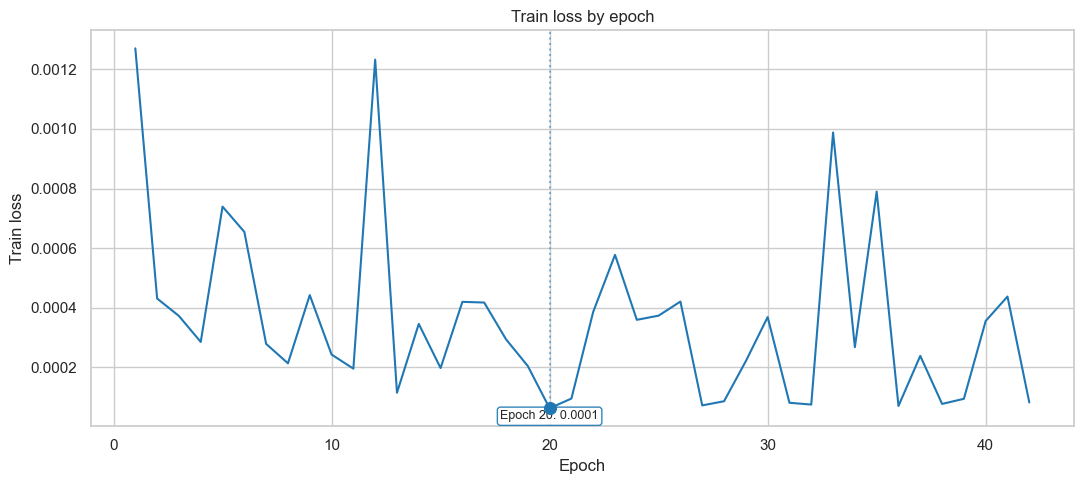

Lowest train loss: 0.0001 at epochs [20]


In [115]:
# Plot train loss across epochs in its original units.
sbn.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(11, 5))
sbn.lineplot(data=history_df, x='epoch', y='train_loss', ax=ax, color='tab:blue')


# Mark every epoch tied for the lowest train loss.
metric_value = history_df['train_loss'].min()
best_rows = history_df.loc[history_df['train_loss'] == metric_value]
metric_epochs = best_rows['epoch'].astype(int).tolist()
ax.scatter(best_rows['epoch'], best_rows['train_loss'], color='tab:blue', s=70, zorder=5)
for metric_epoch in metric_epochs:
    ax.axvline(metric_epoch, color='tab:blue', linestyle=':', alpha=0.5)

# Finalize the axes before positioning labels in display coordinates.
ax.set(xlabel='Epoch', ylabel='Train loss', title='Train loss by epoch')
fig.tight_layout()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
plot_bounds = ax.get_window_extent(renderer)
placed_boxes = []


# Find a nearby label position with room for the entire text box.
# Connector lines keep displaced labels attached to their exact dots.
for metric_epoch in metric_epochs:
    label = f'Epoch {metric_epoch}: {metric_value:.4f}'
    probe = ax.text(0, 0, label, fontsize=9)
    extent = probe.get_window_extent(renderer)
    width, height = extent.width + 10, extent.height + 8
    probe.remove()
    point_x, point_y = ax.transData.transform((metric_epoch, metric_value))
    candidates = []
    for offset_y in (22, -22, 48, -48, 74, -74, 100, -100, 126, -126):
        for offset_x in (0, -width, width, -2 * width, 2 * width):
            x = np.clip(point_x + offset_x, plot_bounds.x0 + width / 2, plot_bounds.x1 - width / 2)
            y = np.clip(point_y + offset_y, plot_bounds.y0 + height / 2, plot_bounds.y1 - height / 2)
            box = (x - width / 2, y - height / 2, x + width / 2, y + height / 2)
            overlap = sum(
                max(0, min(box[2], other[2]) - max(box[0], other[0]))
                * max(0, min(box[3], other[3]) - max(box[1], other[1]))
                for other in placed_boxes
            )
            distance = (x - point_x) ** 2 + (y - point_y) ** 2
            candidates.append((overlap, distance, x, y, box))
    _, _, label_x, label_y, box = min(candidates, key=lambda item: item[:2])
    placed_boxes.append(box)
    label_position = ax.transAxes.inverted().transform((label_x, label_y))
    ax.annotate(
        label, xy=(metric_epoch, metric_value), xycoords='data',
        xytext=label_position, textcoords='axes fraction',
        ha='center', va='center', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='tab:blue', alpha=0.9),
        arrowprops=dict(arrowstyle='-', color='tab:blue', linewidth=0.8, shrinkB=5),
    )

plt.show()
print(f'Lowest train loss: {metric_value:.4f} at epochs {metric_epochs}')


### Plot the Test loss.

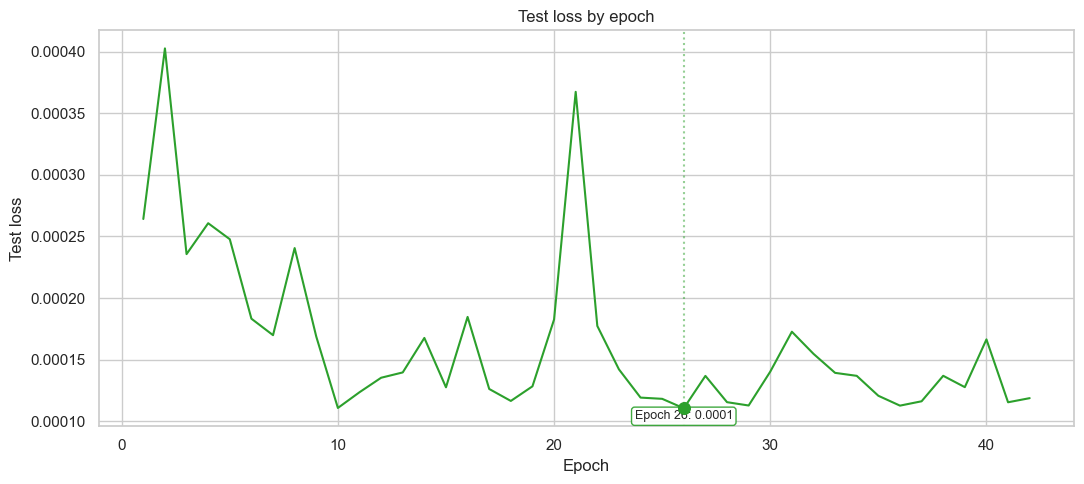

Lowest test loss: 0.0001 at epochs [26]


In [116]:
# Plot test loss across epochs in its original units.
sbn.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(11, 5))
sbn.lineplot(data=history_df, x='epoch', y='test_loss', ax=ax, color='tab:green')


# Mark every epoch tied for the lowest test loss.
metric_value = history_df['test_loss'].min()
best_rows = history_df.loc[history_df['test_loss'] == metric_value]
metric_epochs = best_rows['epoch'].astype(int).tolist()
ax.scatter(best_rows['epoch'], best_rows['test_loss'], color='tab:green', s=70, zorder=5)
for metric_epoch in metric_epochs:
    ax.axvline(metric_epoch, color='tab:green', linestyle=':', alpha=0.5)

# Finalize the axes before positioning labels in display coordinates.
ax.set(xlabel='Epoch', ylabel='Test loss', title='Test loss by epoch')
fig.tight_layout()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
plot_bounds = ax.get_window_extent(renderer)
placed_boxes = []


# Find a nearby label position with room for the entire text box.
# Connector lines keep displaced labels attached to their exact dots.
for metric_epoch in metric_epochs:
    label = f'Epoch {metric_epoch}: {metric_value:.4f}'
    probe = ax.text(0, 0, label, fontsize=9)
    extent = probe.get_window_extent(renderer)
    width, height = extent.width + 10, extent.height + 8
    probe.remove()
    point_x, point_y = ax.transData.transform((metric_epoch, metric_value))
    candidates = []
    for offset_y in (22, -22, 48, -48, 74, -74, 100, -100, 126, -126):
        for offset_x in (0, -width, width, -2 * width, 2 * width):
            x = np.clip(point_x + offset_x, plot_bounds.x0 + width / 2, plot_bounds.x1 - width / 2)
            y = np.clip(point_y + offset_y, plot_bounds.y0 + height / 2, plot_bounds.y1 - height / 2)
            box = (x - width / 2, y - height / 2, x + width / 2, y + height / 2)
            overlap = sum(
                max(0, min(box[2], other[2]) - max(box[0], other[0]))
                * max(0, min(box[3], other[3]) - max(box[1], other[1]))
                for other in placed_boxes
            )
            distance = (x - point_x) ** 2 + (y - point_y) ** 2
            candidates.append((overlap, distance, x, y, box))
    _, _, label_x, label_y, box = min(candidates, key=lambda item: item[:2])
    placed_boxes.append(box)
    label_position = ax.transAxes.inverted().transform((label_x, label_y))
    ax.annotate(
        label, xy=(metric_epoch, metric_value), xycoords='data',
        xytext=label_position, textcoords='axes fraction',
        ha='center', va='center', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='tab:green', alpha=0.9),
        arrowprops=dict(arrowstyle='-', color='tab:green', linewidth=0.8, shrinkB=5),
    )

plt.show()
print(f'Lowest test loss: {metric_value:.4f} at epochs {metric_epochs}')


### Plot the Test Accuracy.

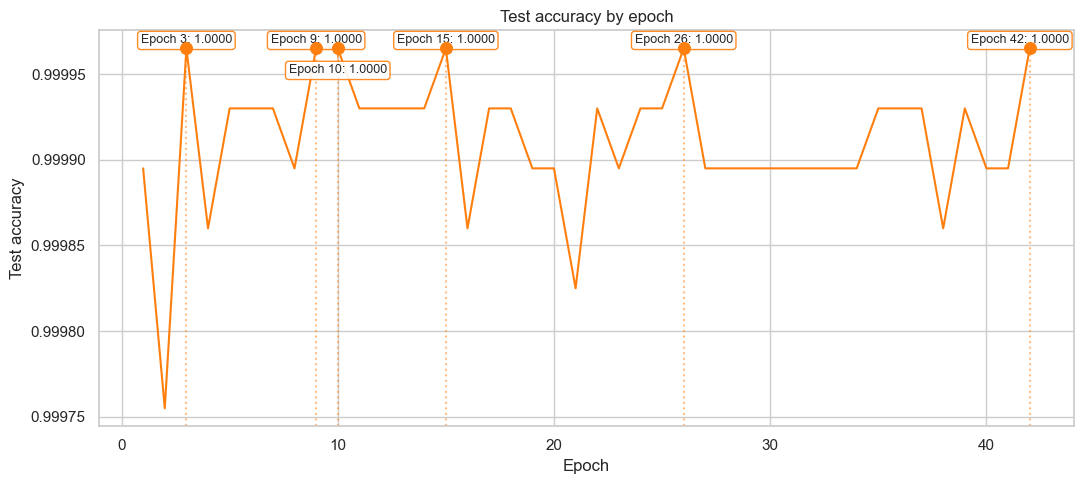

Highest test accuracy: 1.0000 at epochs [3, 9, 10, 15, 26, 42]


In [117]:
# Plot test accuracy across epochs in its original units.
sbn.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(11, 5))
sbn.lineplot(data=history_df, x='epoch', y='test_accuracy', ax=ax, color='tab:orange')


# Mark every epoch tied for the highest test accuracy.
metric_value = history_df['test_accuracy'].max()
best_rows = history_df.loc[history_df['test_accuracy'] == metric_value]
metric_epochs = best_rows['epoch'].astype(int).tolist()
ax.scatter(best_rows['epoch'], best_rows['test_accuracy'], color='tab:orange', s=70, zorder=5)
for metric_epoch in metric_epochs:
    ax.axvline(metric_epoch, color='tab:orange', linestyle=':', alpha=0.5)

# Finalize the axes before positioning labels in display coordinates.
ax.set(xlabel='Epoch', ylabel='Test accuracy', title='Test accuracy by epoch')
fig.tight_layout()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
plot_bounds = ax.get_window_extent(renderer)
placed_boxes = []


# Find a nearby label position with room for the entire text box.
# Connector lines keep displaced labels attached to their exact dots.
for metric_epoch in metric_epochs:
    label = f'Epoch {metric_epoch}: {metric_value:.4f}'
    probe = ax.text(0, 0, label, fontsize=9)
    extent = probe.get_window_extent(renderer)
    width, height = extent.width + 10, extent.height + 8
    probe.remove()
    point_x, point_y = ax.transData.transform((metric_epoch, metric_value))
    candidates = []
    for offset_y in (22, -22, 48, -48, 74, -74, 100, -100, 126, -126):
        for offset_x in (0, -width, width, -2 * width, 2 * width):
            x = np.clip(point_x + offset_x, plot_bounds.x0 + width / 2, plot_bounds.x1 - width / 2)
            y = np.clip(point_y + offset_y, plot_bounds.y0 + height / 2, plot_bounds.y1 - height / 2)
            box = (x - width / 2, y - height / 2, x + width / 2, y + height / 2)
            overlap = sum(
                max(0, min(box[2], other[2]) - max(box[0], other[0]))
                * max(0, min(box[3], other[3]) - max(box[1], other[1]))
                for other in placed_boxes
            )
            distance = (x - point_x) ** 2 + (y - point_y) ** 2
            candidates.append((overlap, distance, x, y, box))
    _, _, label_x, label_y, box = min(candidates, key=lambda item: item[:2])
    placed_boxes.append(box)
    label_position = ax.transAxes.inverted().transform((label_x, label_y))
    ax.annotate(
        label, xy=(metric_epoch, metric_value), xycoords='data',
        xytext=label_position, textcoords='axes fraction',
        ha='center', va='center', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='tab:orange', alpha=0.9),
        arrowprops=dict(arrowstyle='-', color='tab:orange', linewidth=0.8, shrinkB=5),
    )

plt.show()
print(f'Highest test accuracy: {metric_value:.4f} at epochs {metric_epochs}')


---

# Evaluation

### Load the best checkpointed model.
The model is picked based on lowest Test Loss, cross-referencing with highest Test Accuracy.

Train Loss is graphed as a third measure.

In [118]:
# Load epoch 26 from this training run onto the selected device.
loaded_checkpoint_path = Path('.models/20261015_095219_939710/epoch_026.pt')
# This local checkpoint contains sklearn preprocessing objects as well as tensors.
loaded_checkpoint = torch.load(loaded_checkpoint_path, map_location='cpu', weights_only=False)
loaded_epoch = loaded_checkpoint['epoch']
config = loaded_checkpoint['model_config']


# Rebuild the model with the checkpoint's original embedding bins and dimensions.
loaded_embeddings = rtdl_num_embeddings.PiecewiseLinearEmbeddings(
    config['bins'],
    d_embedding=config['d_embedding'],
    activation=config['activation'],
    version=config['version'],
)
model = tabm.TabM.make(
    n_num_features=config['n_num_features'],
    cat_cardinalities=config['cat_cardinalities'],
    d_out=config['d_out'],
    num_embeddings=loaded_embeddings,
).to(device)
model.load_state_dict(loaded_checkpoint['model'])
model.eval()


# Summary.
print(f'Loaded epoch {loaded_epoch}: {loaded_checkpoint_path}')
print(f'Saved metrics: {loaded_checkpoint["metrics"]}')


Loaded epoch 26: .models/20261015_095219_939710/epoch_026.pt
Saved metrics: {'epoch': 26, 'train_loss': 0.0004210530699461873, 'test_loss': 0.00011060855635797184, 'test_accuracy': 0.9999649884461872}


/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddings.py:340: UserWarning: The 5-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddings.py:340: UserWarning: The 13-th feature has just two bin edges, which means only one bin. Strictly speaking, using a single bin for the piecewise-linear encoding should not break anything, but it is the same as using sklearn.preprocessing.MinMaxScaler
  warnings.warn(
/Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Network_Intrusion/.venv/lib/python3.9/site-packages/rtdl_num_embeddin

### Process the Eval split.

In [119]:
# Apply the saved preprocessing to the held-out eval data.
# This keeps evaluation consistent even if preprocessing cells have been rerun.
loaded_num_cols = loaded_checkpoint['num_cols']
loaded_cat_cols = loaded_checkpoint['cat_cols']
loaded_numeric_preprocessing = loaded_checkpoint['numeric_preprocessing']
loaded_category_maps = loaded_checkpoint['category_maps']
eval_numeric = (
    loaded_numeric_preprocessing.transform(
        X_eval[loaded_num_cols].to_numpy(dtype=np.float32, na_value=np.nan)
    ).astype(np.float32)
    if loaded_num_cols else np.empty((len(X_eval), 0), dtype=np.float32)
)
loaded_eval_tensors = {
    'x_num': torch.as_tensor(eval_numeric, dtype=torch.float32, device=device),
    'y': torch.as_tensor(y_eval.to_numpy(dtype=np.int64), device=device),
}
if loaded_cat_cols:
    eval_encoded_columns = []
    for column in loaded_cat_cols:
        values = X_eval[column].astype('string')
        encoded = values.map(loaded_category_maps[column]).fillna(0)
        encoded = encoded.mask(values.isna(), 1)
        eval_encoded_columns.append(encoded.to_numpy(dtype=np.int64))
    loaded_eval_tensors['x_cat'] = torch.as_tensor(
        np.column_stack(eval_encoded_columns), dtype=torch.int64, device=device,
    )

### Evaluate.

In [120]:
# Evaluate the selected checkpoint without depending on training helper cells.
model.eval()
eval_labels = loaded_eval_tensors['y'].cpu().numpy()
eval_batches = []
with torch.inference_mode():
    for start in range(0, len(eval_labels), 1024):
        stop = start + 1024
        logits = model(
            loaded_eval_tensors['x_num'][start:stop],
            loaded_eval_tensors['x_cat'][start:stop] if 'x_cat' in loaded_eval_tensors else None,
        ).float()
        eval_batches.append(logits.softmax(dim=-1).mean(dim=1).cpu())
eval_probabilities = torch.cat(eval_batches).numpy()
print(f'Evaluating checkpoint epoch {loaded_epoch}: {loaded_checkpoint_path}')
eval_attack_probability = eval_probabilities[:, 1]
eval_predictions = eval_probabilities.argmax(axis=1)


# Summarize classification quality and performance on the attack class (1).
eval_metrics = pd.Series({
    'log_loss': sklearn.metrics.log_loss(eval_labels, eval_probabilities, labels=[0, 1]),
    'accuracy': sklearn.metrics.accuracy_score(eval_labels, eval_predictions),
    'precision': sklearn.metrics.precision_score(eval_labels, eval_predictions, zero_division=0),
    'recall': sklearn.metrics.recall_score(eval_labels, eval_predictions, zero_division=0),
    'f1': sklearn.metrics.f1_score(eval_labels, eval_predictions, zero_division=0),
    'roc_auc': sklearn.metrics.roc_auc_score(eval_labels, eval_attack_probability),
    'average_precision': sklearn.metrics.average_precision_score(eval_labels, eval_attack_probability),
}, name='Evaluation score')
print(eval_metrics.round(4).to_string())


# Show per-class results and the confusion matrix.
print(sklearn.metrics.classification_report(
    eval_labels, eval_predictions, labels=[0, 1],
    target_names=['Normal (0)', 'Attack (1)'], zero_division=0,
))
confusion_df = pd.DataFrame(
    sklearn.metrics.confusion_matrix(eval_labels, eval_predictions, labels=[0, 1]),
    index=['Actual normal', 'Actual attack'],
    columns=['Predicted normal', 'Predicted attack'],
)
print(confusion_df.to_string())


Evaluating checkpoint epoch 26: .models/20261015_095219_939710/epoch_026.pt
log_loss             0.0002
accuracy             0.9999
precision            0.9999
recall               1.0000
f1                   1.0000
roc_auc              1.0000
average_precision    1.0000
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00      6298
  Attack (1)       1.00      1.00      1.00     22264

    accuracy                           1.00     28562
   macro avg       1.00      1.00      1.00     28562
weighted avg       1.00      1.00      1.00     28562

               Predicted normal  Predicted attack
Actual normal              6296                 2
Actual attack                 0             22264
